# 1064 nm Temporal Characterization

**Source:** Thorlabs GSL106A, fiber output, external trigger intended at 200 kHz.  
**Detector:** legacy Thorlabs PDA36A at the 0 dB gain setting.  
**Oscilloscope:** Keysight/Agilent DSO6104A. Quantitative records use the scope's internal 50 Ω input; 1 MΩ records are retained as an explicit improper-termination comparison. CH3 is the function-generator output split by a BNC T to the laser trigger input and oscilloscope.

The legacy PDA36A 0 dB settings used here are:

- nominal bandwidth: 10 MHz;
- transimpedance: 0.750 kV/A into 50 Ω;
- transimpedance: 1.51 kV/A into high impedance;
- manufacturer warning: at near-infrared wavelengths, photodiode rise time can further limit effective bandwidth.

The 10 MHz bandwidth corresponds to a nominal step rise-time scale of about \(0.35/B=35\) ns. It does **not** uniquely define the detector's impulse-response FWHM, so no arbitrary Gaussian deconvolution is performed.

In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def _locate_project_root(start=None):
    """Find the extracted project folder even if Jupyter was launched one directory above it."""
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for base in candidates:
        if (base / "laser_characterization.py").is_file() and (base / "outputs").is_dir():
            return base.resolve()
        try:
            children = sorted(base.glob("Laser_Characterization_Project*")) + sorted(base.glob("laser_characterization_project*"))
        except OSError:
            children = []
        for child in children:
            if child.is_dir() and (child / "laser_characterization.py").is_file() and (child / "outputs").is_dir():
                return child.resolve()
    raise FileNotFoundError(
        "Could not locate the laser-characterization project folder. Keep the notebooks, "
        "laser_characterization.py, laser_characterization_core.py, and outputs/ together."
    )

PROJECT_ROOT = _locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from laser_characterization import *

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
with (PROJECT_ROOT / "experiment_metadata.json").open() as handle:
    EXPERIMENT = json.load(handle)

# Raw data are optional for viewing the complete precomputed analysis.
# If present, they enable reconstruction of raw-data plots.
try:
    DATA_ROOT = find_data_root(PROJECT_ROOT)
except FileNotFoundError:
    DATA_ROOT = None
    for candidate in [
        PROJECT_ROOT / "data" / "532 and 1064",
        PROJECT_ROOT.parent / "532 and 1064",
        PROJECT_ROOT.parent / "data" / "532 and 1064",
    ]:
        if candidate.is_dir():
            DATA_ROOT = candidate.resolve()
            break
if DATA_ROOT is None:
    warnings.warn(
        "Raw data folder not found. This is OK: all precomputed result tables are included, "
        "and raw-data-only plots will be skipped."
    )


def source_path(stored_path):
    """Resolve a portable path stored relative to the `532 and 1064` data root."""
    p = Path(str(stored_path))
    if p.is_absolute() and p.exists():
        return p
    if DATA_ROOT is None:
        return p
    # Current V4 tables store paths relative to DATA_ROOT.
    q = Path(DATA_ROOT) / p
    if q.exists():
        return q
    # Backward compatibility for older absolute paths.
    parts = p.parts
    if "532 and 1064" in parts:
        i = parts.index("532 and 1064")
        q = Path(DATA_ROOT) / Path(*parts[i+1:])
        if q.exists():
            return q
    return q

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_ROOT if DATA_ROOT else "not mounted (using included precomputed results)")


Project: <project root>
Raw data: <project root>\data\532 and 1064


In [2]:
temporal = pd.read_csv(OUTPUT_DIR / "temporal_record_metrics.csv")
mode_summary = pd.read_csv(OUTPUT_DIR / "temporal_mode_summary.csv")
power_inputs = pd.read_csv(OUTPUT_DIR / "average_power_inputs.csv")

display(mode_summary.round(5))

,mode,file,record_duration_us,sample_interval_ns,n_cycles,amplitude_v,fwhm_ns,rise_10_90_ns,fall_90_10_ns,equivalent_width_ns,amplitude_cv_percent,area_cv_percent,rep_rate_measured_hz,trigger_edge_count,trigger_edge_residual_rms_ps,trigger_to_electrical_peak_median_ns,trigger_to_electrical_peak_std_ns,trigger_delay_repeatability_usable,pulse_resolution_class,measured_fwhm_interpretation,absolute_optical_pulse_width_reportable,intrinsic_laser_timing_jitter_reportable,timing_metric_scope,absolute_power_calibrated,ch1_imp,ch1_bw,ch3_imp,trigger_source,trigger_coup,acquisition_mode,acquisition_realtime,scope_model,scope_serial
0,1_ns,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_TimeDiv_20us.csv,199.99975,0.25,40,0.01706,32.36804,18.74556,20.66402,58.02107,14.46010,12.03778,200000.29511,40,463.83489,61.12500,2.03152,True,unresolved_detector_limited,electrical detector-chain response; do not report as optical pulse duration,False,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter,False,50 Ohm,Off,1M Ohm,CHAN3,DC,NORM,On,DSO6104A,MY44003673
1,65_ns,Mode_65ns_ND_1_Gain_0db_ExtTrigger_200kHz_TimeDiv_50us.csv,499.99975,0.25,100,0.09247,49.02496,32.60722,23.73296,81.88008,2.54305,5.10384,200000.37040,100,343.25822,110.25000,2.92155,True,partially_resolved_detector_convolved,measured electrical FWHM is detector-convolved and is not a calibrated 65 ns optical width,False,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter,False,50 Ohm,Off,1M Ohm,CHAN3,DC,NORM,On,DSO6104A,MY44003673
2,picosecond,Mode_ps_ND_0_Gain_0db_ExtTrigger_200kHz_TimeDiv_50us.csv,499.99975,0.25,100,0.00221,20.88957,21.61698,25.52272,64.72689,13.54479,7.90290,200000.38372,100,452.21219,59.42187,45.69588,False,unresolved_detector_limited,electrical detector-chain response; do not report as optical pulse duration,False,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter,False,50 Ohm,Off,1M Ohm,CHAN3,DC,NORM,On,DSO6104A,MY44003673


## Scope metadata audit

The exported setup text, rather than the folder label alone, is used to verify channel termination, bandwidth limit, trigger source, trigger coupling, acquisition mode, and channel skew. The quantitative 50 Ω records show CH1 at 50 Ω, CH3 at 1 MΩ, bandwidth limit off, normal real-time acquisition, trigger source CH3, DC trigger coupling, and zero stored channel skew.

In [3]:
setup_cols = [
    "termination", "ch1_imp", "ch1_bw", "ch1_skew", "ch3_imp", "ch3_bw", "ch3_skew",
    "trigger_source", "trigger_coup", "trigger_slope", "acquisition_mode", "acquisition_realtime",
]
display(temporal[setup_cols].drop_duplicates().reset_index(drop=True))

print("All quantitative 50 Ω records consistent with folder termination:",
      bool(temporal.loc[temporal.termination.eq("50ohm"), "scope_input_termination_consistent"].all()))

,termination,ch1_imp,ch1_bw,ch1_skew,ch3_imp,ch3_bw,ch3_skew,trigger_source,trigger_coup,trigger_slope,acquisition_mode,acquisition_realtime
0,1Mohm,1M Ohm,Off,0 s,1M Ohm,Off,0 s,CHAN2,DC,POS,NORM,On
1,1Mohm,1M Ohm,Off,0 s,1M Ohm,Off,0 s,CHAN1,DC,POS,NORM,On
2,50ohm,50 Ohm,Off,0 s,1M Ohm,Off,0 s,CHAN3,DC,POS,NORM,On


All quantitative 50 Ω records consistent with folder termination: True


## Long-record waveforms and 200 kHz repetition rate

The long records contain many cycles. CH3 edges have sample-level ringing/noise, so a simple midpoint crossing can count multiple transitions. The analysis uses a Schmitt/hysteretic state machine and confirms the result against the waveform's 200 kHz fundamental. The long 50 Ω records give 200.0003–200.0004 kHz.

In [4]:
long_records = (
    temporal[temporal.termination.eq("50ohm")]
    .sort_values("record_duration_s")
    .groupby("mode", as_index=False, group_keys=False)
    .tail(1)
    .sort_values("mode")
)
display(long_records[[
    "mode", "file", "record_duration_us", "sample_interval_ns", "trigger_edge_count",
    "rep_rate_measured_hz", "trigger_edge_residual_rms_ps",
]].round(6))

,mode,file,record_duration_us,sample_interval_ns,trigger_edge_count,rep_rate_measured_hz,trigger_edge_residual_rms_ps
12,1_ns,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_TimeDiv_20us.csv,199.99975,0.25,40,200000.295107,463.834885
15,65_ns,Mode_65ns_ND_1_Gain_0db_ExtTrigger_200kHz_TimeDiv_50us.csv,499.99975,0.25,100,200000.370400,343.258215
18,picosecond,Mode_ps_ND_0_Gain_0db_ExtTrigger_200kHz_TimeDiv_50us.csv,499.99975,0.25,100,200000.383722,452.212186


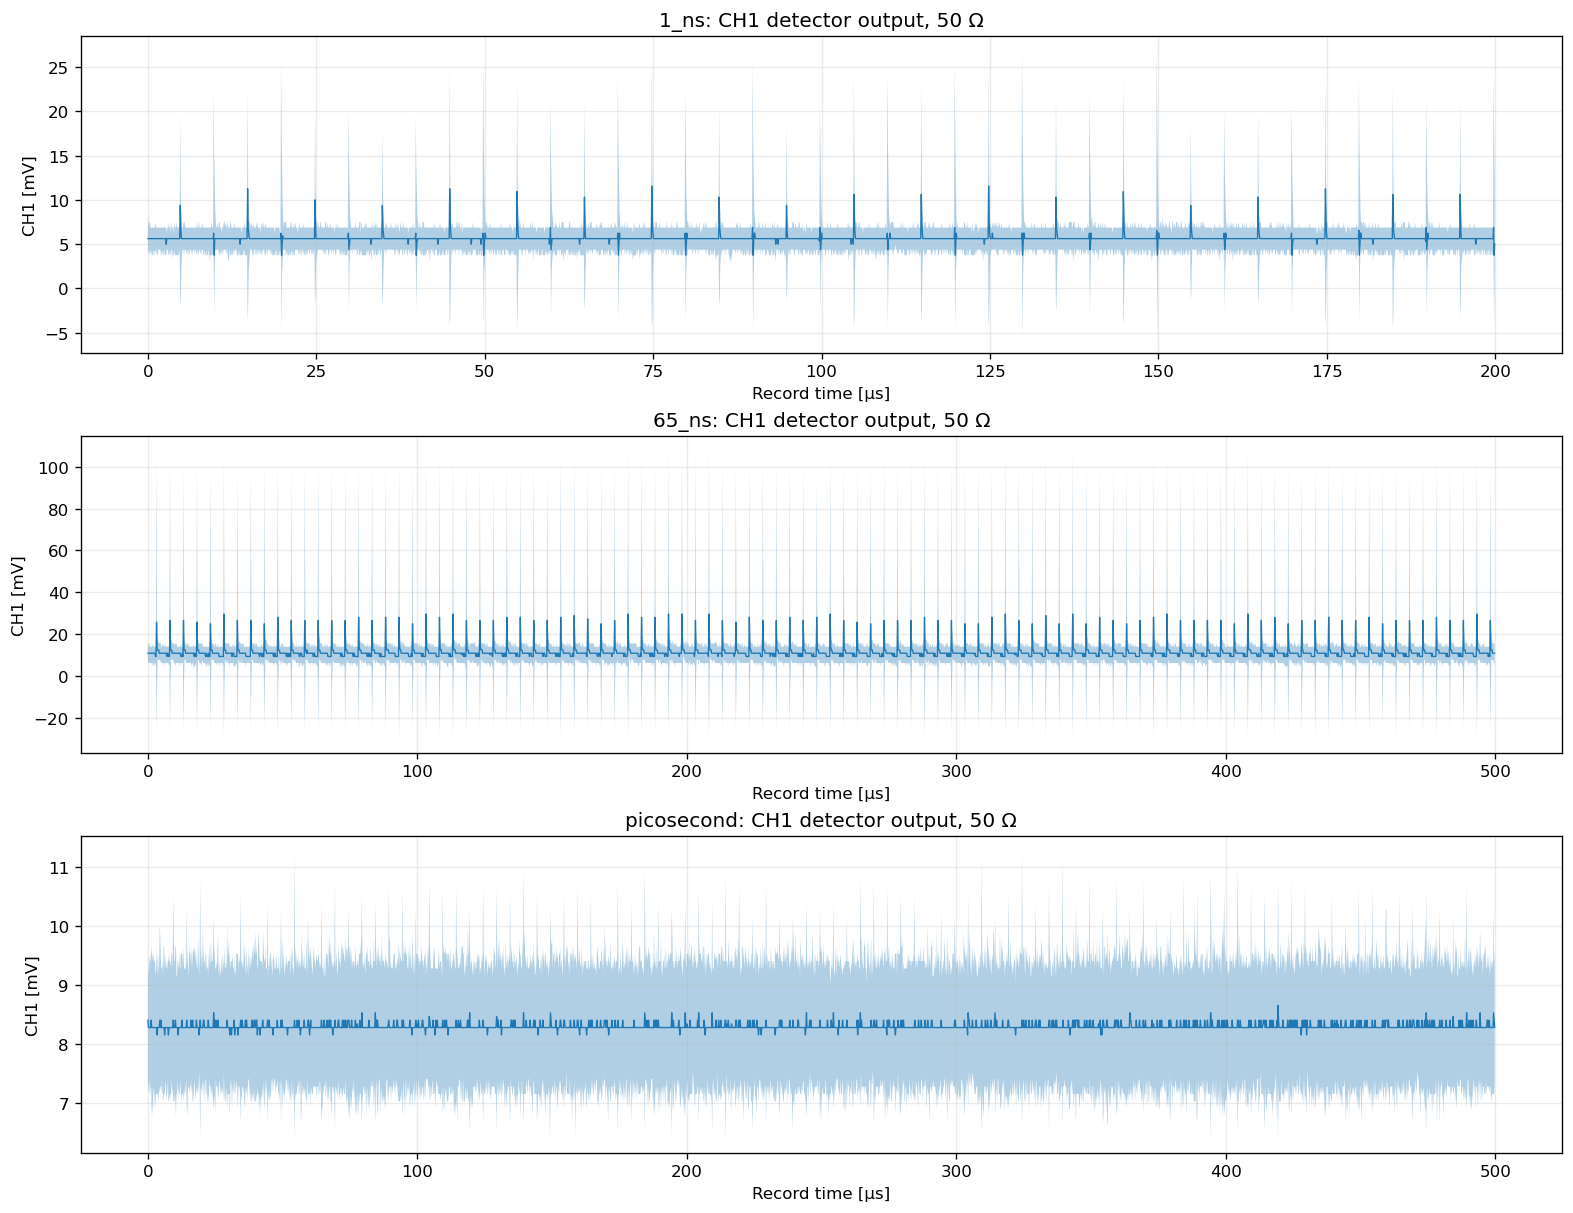

In [5]:
if DATA_ROOT is not None:
    selected = {row["mode"]: source_path(row["path"]) for _, row in long_records.iterrows()}
    fig, axes = plt.subplots(3, 1, figsize=(13, 10), constrained_layout=True)
    for ax, (mode, path) in zip(axes, selected.items()):
        data, _ = read_scope_csv(path)
        env = minmax_envelope(data.time_s.to_numpy(), data.ch1_v.to_numpy(), target_bins=2500)
        time_us = (env.x - env.x.iloc[0]) * 1e6
        ax.fill_between(time_us, env.y_min * 1e3, env.y_max * 1e3, alpha=0.35)
        ax.plot(time_us, env.y_median * 1e3, linewidth=0.8)
        ax.set_title(f"{mode}: CH1 detector output, 50 Ω")
        ax.set_xlabel("Record time [µs]")
        ax.set_ylabel("CH1 [mV]")
    fig.savefig(FIGURE_DIR / "temporal_long_records_v2.png", bbox_inches="tight")
    plt.show()
else:
    print("Raw data not mounted.")

## Coherently averaged electrical pulse shapes

The plotted widths are **electrical detector-chain widths**. The picosecond and nominal 1 ns optical pulses are far faster than the PDA36A response. The 65 ns mode produces a broader electrical waveform, but the measured 49.0 ns FWHM is still detector-convolved and is not a calibrated optical duration.

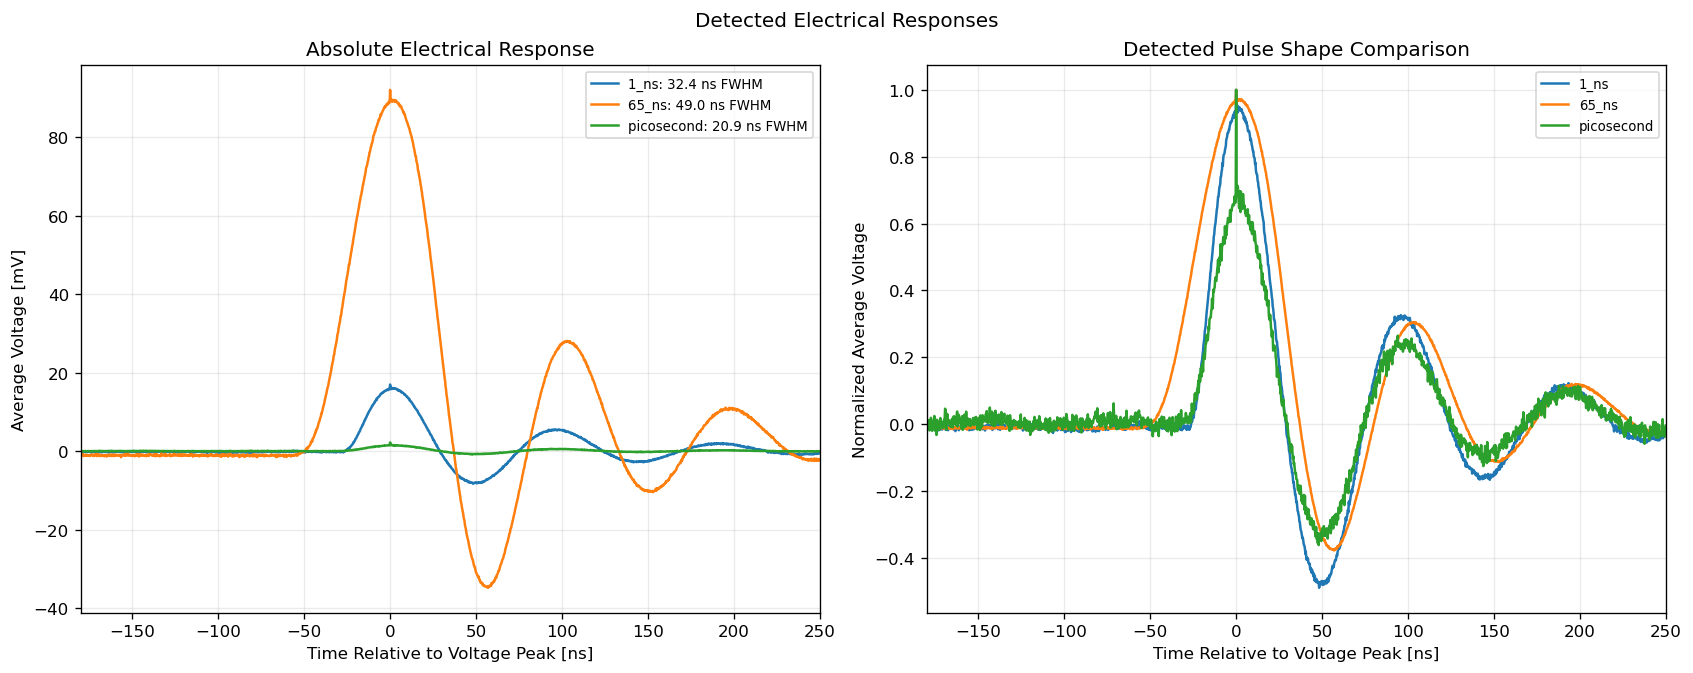

In [6]:
if DATA_ROOT is not None:
    cfg = TemporalConfig()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    recomputed = []
    for _, row in long_records.iterrows():
        result, wave = analyze_scope_record(source_path(row["path"]), cfg, keep_waveform=True)
        folded = wave["folded"]
        phase_ns = folded["phase_s"] * 1e9
        mean_mv = folded["mean_v"] * 1e3
        label = f'{row["mode"]}: {result["fwhm_ns"]:.1f} ns FWHM'
        axes[0].plot(phase_ns, mean_mv, label=label)
        display_window = (phase_ns >= -180) & (phase_ns <= 250)
        scale = max(np.max(np.abs(mean_mv[display_window])), 1e-15)
        axes[1].plot(phase_ns, mean_mv / scale, label=row["mode"])
        recomputed.append(result)
    for ax in axes:
        ax.set_xlim(-180, 250)
        ax.set_xlabel("Time Relative to Voltage Peak [ns]")
    axes[0].set_ylabel("Average Voltage [mV]")
    axes[0].set_title("Absolute Electrical Response")
    axes[0].legend(fontsize=8)
    axes[1].set_ylabel("Normalized Average Voltage")
    axes[1].set_title("Detected Pulse Shape Comparison")
    axes[1].legend(fontsize=8)
    fig.suptitle("Detected Electrical Responses")
    fig.savefig(FIGURE_DIR / "temporal_coherent_average_v2.png", bbox_inches="tight")
    plt.show()
else:
    print("Raw data not mounted.")

In [7]:
summary_cols = [
    "mode", "amplitude_v", "fwhm_ns", "rise_10_90_ns", "fall_90_10_ns",
    "amplitude_cv_percent", "area_cv_percent", "rep_rate_measured_hz",
    "pulse_resolution_class", "measured_fwhm_interpretation",
]
display(mode_summary[summary_cols].round(5))

,mode,amplitude_v,fwhm_ns,rise_10_90_ns,fall_90_10_ns,amplitude_cv_percent,area_cv_percent,rep_rate_measured_hz,pulse_resolution_class,measured_fwhm_interpretation
0,1_ns,0.01706,32.36804,18.74556,20.66402,14.46010,12.03778,200000.29511,unresolved_detector_limited,electrical detector-chain response; do not report as optical pulse duration
1,65_ns,0.09247,49.02496,32.60722,23.73296,2.54305,5.10384,200000.37040,partially_resolved_detector_convolved,measured electrical FWHM is detector-convolved and is not a calibrated 65 ns optical width
2,picosecond,0.00221,20.88957,21.61698,25.52272,13.54479,7.90290,200000.38372,unresolved_detector_limited,electrical detector-chain response; do not report as optical pulse duration


### What is trustworthy

- **Repetition rate:** high confidence as a measurement-chain result; approximately 200.000 kHz.
- **Relative electrical waveform shape:** high confidence for the properly terminated 50 Ω records.
- **65 ns versus fast-mode distinction:** high confidence; the 65 ns mode is electrically broader.
- **Optical 1 ns or picosecond duration:** not supported by this detector.
- **Optical 65 ns duration:** not calibrated; the detector transfer function at 1064 nm is not measured.
- **Pulse-to-pulse amplitude/area CV:** an electrical stability metric that includes detector and oscilloscope noise, especially important for the small picosecond-mode signal.

## Trigger-to-electrical-peak timing and jitter

The long records have 0.25 ns sample spacing. The GSL106A's manufacturer timing-jitter specification is much smaller than that sampling interval. Consequently, neither the CH3 edge residual nor the CH3-to-CH1 peak spread should be labeled intrinsic laser jitter. They include the function generator, scope sampling/threshold noise, laser, detector response, cable delays, and the absence of a deskew calibration.

In [8]:
delay_cols = [
    "mode", "trigger_edge_residual_rms_ps", "trigger_to_electrical_peak_median_ns",
    "trigger_to_electrical_peak_std_ns", "trigger_delay_repeatability_usable",
    "intrinsic_laser_timing_jitter_reportable", "timing_metric_scope",
]
display(mode_summary[delay_cols].round(4))

,mode,trigger_edge_residual_rms_ps,trigger_to_electrical_peak_median_ns,trigger_to_electrical_peak_std_ns,trigger_delay_repeatability_usable,intrinsic_laser_timing_jitter_reportable,timing_metric_scope
0,1_ns,463.8349,61.1250,2.0315,True,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter
1,65_ns,343.2582,110.2500,2.9216,True,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter
2,picosecond,452.2122,59.4219,45.6959,False,False,function generator + scope sampling + laser + detector-chain timing; not intrinsic GSL jitter


The 1 ns and 65 ns records show approximately 2–3 ns repeatability in the electrical-peak delay, but that is not an absolute optical delay. The picosecond-mode delay scatter is much larger because its CH1 signal is small and the per-cycle peak is less stable.

## 50 Ω versus 1 MΩ termination

The 1 MΩ files are useful as a demonstration of why the detector and cable should be terminated consistently. The high-impedance signal can be larger, but cable reflections and altered transfer function make pulse-shape comparison unreliable. Only the 50 Ω records are used for quantitative waveform conclusions.

In [9]:
comparison = temporal.groupby(["mode", "termination"]).agg(
    records=("file", "count"),
    amplitude_median_v=("amplitude_v", "median"),
    fwhm_median_ns=("fwhm_ns", "median"),
    postpulse_positive_ratio_median=("postpulse_positive_ratio", "median"),
).reset_index()
display(comparison.round(5))

,mode,termination,records,amplitude_median_v,fwhm_median_ns,postpulse_positive_ratio_median
0,1_ns,1Mohm,4,0.03704,31.02292,1.00000
1,1_ns,50ohm,3,0.01706,31.91667,1.00000
2,65_ns,1Mohm,3,0.20422,48.91667,0.98462
3,65_ns,50ohm,3,0.09531,49.91667,1.00000
4,picosecond,1Mohm,3,0.00423,26.45684,0.87830
5,picosecond,50ohm,3,0.00213,16.76667,1.00000


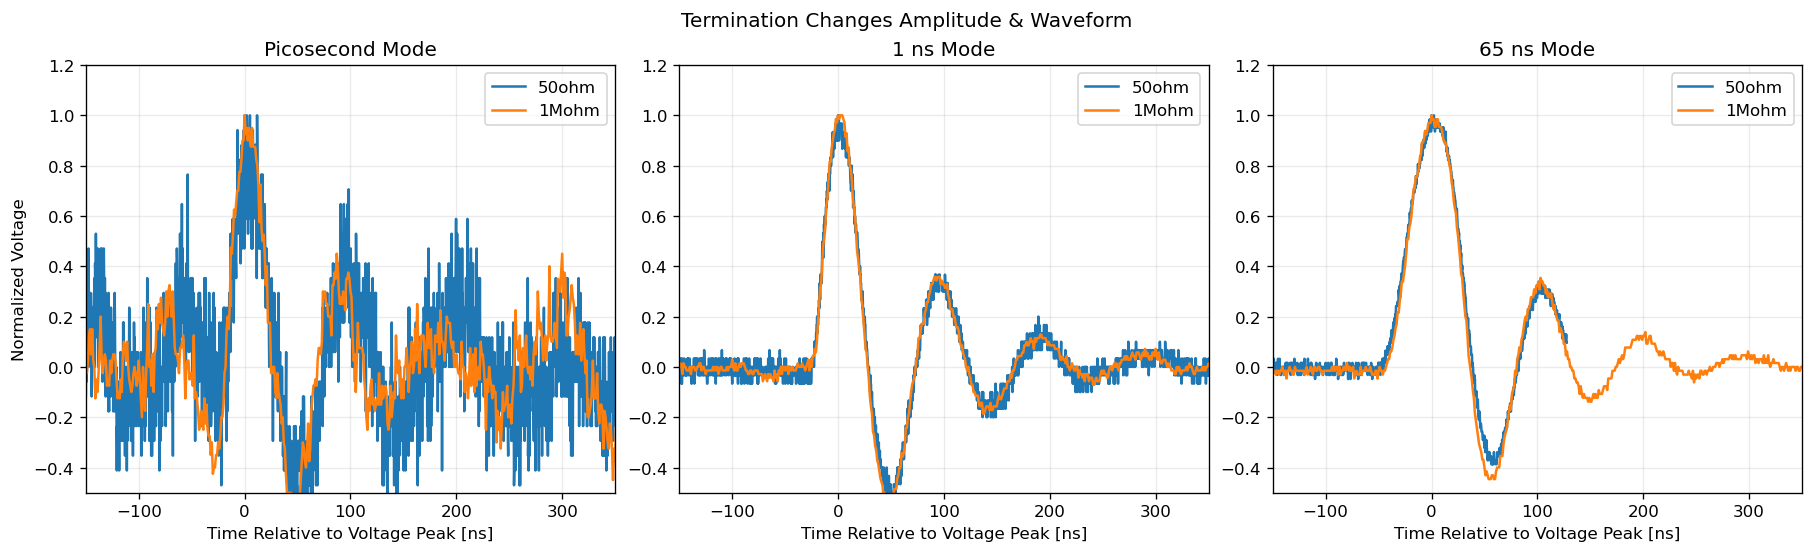

In [22]:
if DATA_ROOT is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    for ax, mode in zip(axes, ["picosecond", "1_ns", "65_ns"]):
        for termination in ["50ohm", "1Mohm"]:
            subset = temporal[(temporal["mode"].eq(mode)) & temporal.termination.eq(termination)]
            row = subset.iloc[(subset.record_duration_s - 2e-5).abs().argmin()]
            data, _ = read_scope_csv(source_path(row["path"]))
            t = data.time_s.to_numpy()
            y = data.ch1_v.to_numpy()
            y = y - np.median(y)
            sign = 1 if np.percentile(y, 99.9) >= -np.percentile(y, 0.1) else -1
            y = sign * y
            peak = np.argmax(y)
            t_ns = (t - t[peak]) * 1e9
            ax.plot(t_ns, y / max(y[peak], 1e-15), label=termination)
    for ax in axes:
        ax.set_xlim(-150, 350)
        ax.set_ylim(-0.5, 1.2)
        ax.set_xlabel("Time Relative to Voltage Peak [ns]")
        ax.legend()
    axes[0].set_ylabel("Normalized Voltage")
    axes[0].set_title("Picosecond Mode")
    axes[1].set_title("1 ns Mode")
    axes[2].set_title("65 ns Mode")
    fig.suptitle("Termination Changes Amplitude & Waveform")
    fig.savefig(FIGURE_DIR / "temporal_termination_v2.png", bbox_inches="tight")
    plt.show()

## Average power and pulse energy

Independent average-power measurements were made with a Thorlabs PM100D console and S121C sensor after the F280APC-1064 collimator and **before** optical attenuation. The symbols reported in the laboratory notes are preserved: `>` is a strict lower bound and `~` is approximate.

For a pulsed mode,

\[
E_{\mathrm{pulse}} = \frac{P_{\mathrm{avg}}}{f_{\mathrm{rep}}}.
\]

This relation gives lower bounds for the ps and 1 ns modes and an observed range for the 65 ns mode. It does not require photodiode responsivity. Peak power is not reported because the optical pulse duration/shape is not independently resolved by the PDA36A measurement chain.

In [11]:
display(power_inputs)

power = power_inputs.copy()
rate_lookup = mode_summary.set_index("mode")["rep_rate_measured_hz"].to_dict()
power["repetition_rate_hz_used"] = power["mode"].map(rate_lookup)
power["pulse_energy_low_nJ"] = (
    power["power_low_mW"] * 1e-3 / power["repetition_rate_hz_used"] * 1e9
)
power["pulse_energy_high_nJ"] = (
    power["power_high_mW"] * 1e-3 / power["repetition_rate_hz_used"] * 1e9
)
power["reported_interpretation"] = np.where(
    power["power_relation"].eq(">"),
    ">" + power["pulse_energy_low_nJ"].map(lambda x: f"{x:.6g}") + " nJ",
    power.apply(
        lambda r: (f"~{r.pulse_energy_low_nJ:.6g}-{r.pulse_energy_high_nJ:.6g} nJ"
                   if pd.notna(r.pulse_energy_high_nJ) else f"~{r.pulse_energy_low_nJ:.6g} nJ"),
        axis=1,
    ),
)
display(power[["mode", "power_relation", "average_power_mW", "power_low_mW", "power_high_mW",
               "repetition_rate_hz_used", "pulse_energy_low_nJ", "pulse_energy_high_nJ",
               "reported_interpretation", "notes"]].round(9))

,mode,power_relation,average_power_mW,power_low_mW,power_high_mW,notes
0,picosecond,>,0.00135,0.00135,NaN,PM100D+S121C; after F280APC-1064 collimator; before attenuation; strict lower bound
1,1_ns,>,0.00940,0.00940,NaN,PM100D+S121C; after F280APC-1064 collimator; before attenuation; strict lower bound
2,65_ns,~,0.33300,0.33000,0.34,PM100D+S121C; observed 330-340 uW; after F280APC-1064 collimator; before attenuation


,mode,power_relation,average_power_mW,power_low_mW,power_high_mW,repetition_rate_hz_used,pulse_energy_low_nJ,pulse_energy_high_nJ,reported_interpretation,notes
0,picosecond,>,0.00135,0.00135,NaN,200000.383722,0.006750,NaN,>0.00674999 nJ,PM100D+S121C; after F280APC-1064 collimator; before attenuation; strict lower bound
1,1_ns,>,0.00940,0.00940,NaN,200000.295107,0.047000,NaN,>0.0469999 nJ,PM100D+S121C; after F280APC-1064 collimator; before attenuation; strict lower bound
2,65_ns,~,0.33300,0.33000,0.34,200000.370400,1.649997,1.699997,~1.65-1.7 nJ,PM100D+S121C; observed 330-340 uW; after F280APC-1064 collimator; before attenuation


## Temporal confidence verdict

| Quantity | Verdict | Interpretation |
|---|---|---|
| Repetition rate | **Supported** | 200.0003–200.0004 kHz from hysteretic CH3 edge timing in long records. |
| Properly terminated electrical pulse shapes | **Supported** | Scope metadata confirms 50 Ω CH1 and bandwidth limit off. |
| Picosecond optical duration | **Not supported** | PDA36A response is orders of magnitude too slow. |
| Nominal 1 ns optical duration | **Not supported** | 32.4 ns measured electrical FWHM is detector limited. |
| Nominal 65 ns optical duration | **Not supported as an absolute width** | 49.0 ns electrical FWHM is detector convolved and rings. |
| Intrinsic GSL timing jitter | **Not supported** | 0.25 ns sampling and detector timing dominate a picosecond-scale specification. |
| Pulse energy | **Supported** | ps: >6.75 pJ; 1 ns: >47.0 pJ; 65 ns: approximately 1.65-1.70 nJ at ~200 kHz. |
| Peak power | **Not supported** | Optical pulse duration/shape and complete power calibration are unavailable. |